# Rajuk Image Level Classifier — Random Forest

**Architecture:** Random Forest ensemble of decision trees on flattened pixel features + PCA.

No neural network, no gradients, no epochs — classical ML ensemble.

**Pipeline:**
1. Mount Drive & Import Libraries
2. Configuration
3. Load Labels
4. Collect Paths & Leakage-Free Split
5. Sample Image Preview
6. Load & Flatten Images into Feature Matrix
7. PCA Dimensionality Reduction
8. Train Random Forest with Grid Search + Cross-Validation
9. Feature Importance (PCA components)
10. Evaluate on Val + Test
11. Classification Report & Confusion Matrix
12. Learning Curves (Train / Val / Test error by dataset size)
13. Save Model
14. Sanity Check

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Import Libraries

In [2]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, log_loss
)

SEED = 42
np.random.seed(SEED)
print('Libraries loaded.')

Libraries loaded.


## 3. Configuration

In [3]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DRIVE_BASE    = Path('/content/drive/MyDrive/ML_Project')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet - Sheet1.csv'

# ── Settings ───────────────────────────────────────────────────────────────────
CLASS_NAMES  = ['negative', 'moderate', 'positive']
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

# 64x64 — good balance of detail vs compute for Random Forest
IMAGE_SIZE   = (64, 64)
INPUT_DIM    = IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3   # 12,288

# PCA: retain 95% variance before feeding into RF
PCA_VARIANCE = 0.95

# Random Forest grid search space
PARAM_GRID = {
    'rf__n_estimators'      : [100, 300, 500],
    'rf__max_depth'         : [None, 20, 40],
    'rf__min_samples_split' : [2, 5, 10],
    'rf__min_samples_leaf'  : [1, 2, 4],
    'rf__max_features'      : ['sqrt', 'log2'],
}

KFOLD_SPLITS  = 5
DATASET_STEPS = [50, 100, 150, 200, 250, 300, 400, 500]

print('Configuration loaded.')
print(f'  Image size : {IMAGE_SIZE}')
print(f'  Input dim  : {INPUT_DIM:,} raw features')
print(f'  PCA target : {PCA_VARIANCE*100:.0f}% variance retained')

Configuration loaded.
  Image size : (64, 64)
  Input dim  : 12,288 raw features
  PCA target : 95% variance retained


## 4. Load Labels

In [4]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target):
    for col in df.columns:
        if normalize_header(col) == target:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate',  'moderate': 'moderate',
               'n': 'negative',  'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(f'No dataset file found at {DRIVE_BASE}.')

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Level column not found.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows | {len(label_map):,} valid labels | source: {source_path.name}')

Loaded 161 rows | 160 valid labels | source: Rajuk_ML_DataSet.xlsx


## 5. Collect Paths & Leakage-Free Split

In [5]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_all_raw(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_all_raw(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_all_raw(REAL_DIR,      label_map)

print(f'Augmented images         : {len(aug_paths):,}')
print(f'Real images              : {len(real_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

# ── Leakage-free split by unique subject ID ────────────────────────────────────
unique_indices     = sorted(set(
    parse_image_index(p.stem.strip()) for p in real_paths
    if parse_image_index(p.stem.strip()) is not None
))
unique_labels_list = [label_map[i] for i in unique_indices]
all_uq             = np.arange(len(unique_indices))

trainval_uq, test_uq = train_test_split(
    all_uq, test_size=0.15, random_state=SEED, stratify=unique_labels_list
)
train_uq, val_uq = train_test_split(
    trainval_uq, test_size=0.15/0.85, random_state=SEED,
    stratify=np.array(unique_labels_list)[trainval_uq]
)

train_img_ids = set(np.array(unique_indices)[train_uq])
val_img_ids   = set(np.array(unique_indices)[val_uq])
test_img_ids  = set(np.array(unique_indices)[test_uq])

train_paths_final, train_labels_final = [], []
val_paths_final,   val_labels_final   = [], []
test_paths_final,  test_labels_final  = [], []

for p, lbl in zip(aug_paths, aug_labels):
    if parse_image_index(p.stem.strip()) in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)

for p, lbl in zip(real_paths, real_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

N_total = len(train_paths_final) + len(val_paths_final) + len(test_paths_final)
print(f'\nLeakage-free split:')
print(f'  Train (real + aug) : {len(train_paths_final):,}  ({100*len(train_paths_final)/N_total:.1f} %)')
print(f'  Val   (real only)  : {len(val_paths_final):,}  ({100*len(val_paths_final)/N_total:.1f} %)')
print(f'  Test  (real only)  : {len(test_paths_final):,}  ({100*len(test_paths_final)/N_total:.1f} %)')

counts = np.bincount(train_labels_final + val_labels_final + test_labels_final,
                     minlength=len(CLASS_NAMES))
print('\nClass distribution:')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

Augmented images         : 2,560
Real images              : 160
Skipped (no index)       : 0
Skipped (no label match) : 0

Leakage-free split:
  Train (real + aug) : 1,904  (97.5 %)
  Val   (real only)  : 24  (1.2 %)
  Test  (real only)  : 24  (1.2 %)

Class distribution:
  negative  : 1,080
  moderate  : 505
  positive  : 367


## 6. 📷 Sample Images — Data Preview

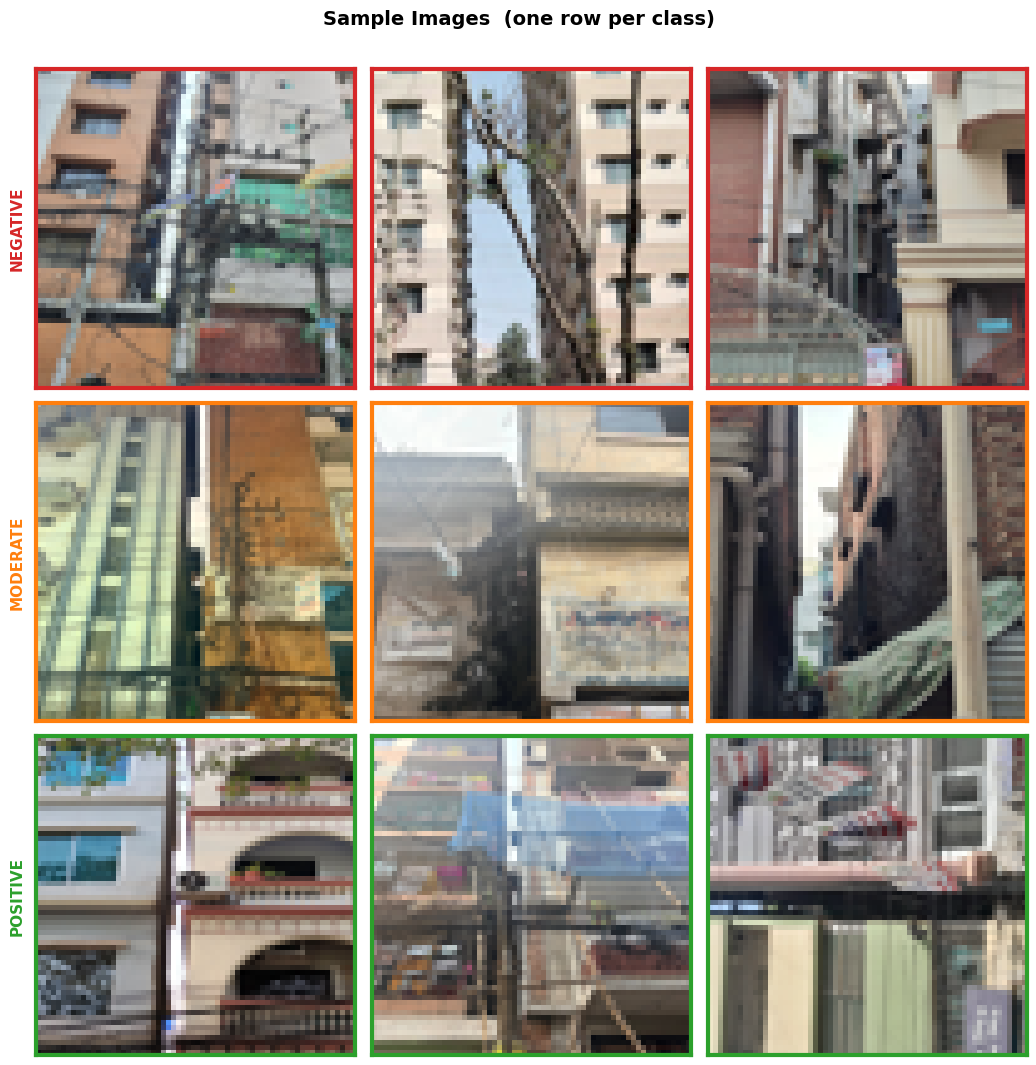

In [6]:
SAMPLES_PER_CLASS = 3
label_to_real_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(real_paths, real_labels):
    label_to_real_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_real_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Load & Flatten Images into Feature Matrix

Each image → resize 64×64 → normalise [0,1] → flatten → **12,288 features**.  
RAM: 2700 × 12,288 × 4 bytes ≈ **133 MB** — very comfortable.

In [7]:
def paths_to_matrix(paths, labels):
    n = len(paths)
    X = np.empty((n, INPUT_DIM), dtype=np.float32)
    y = np.array(labels, dtype=np.int64)
    for i, p in enumerate(paths):
        with Image.open(p) as img:
            arr = np.asarray(
                img.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR),
                dtype=np.float32
            ) / 255.0
        X[i] = arr.flatten()
    return X, y

print('Loading train images …')
X_train, y_train = paths_to_matrix(train_paths_final, train_labels_final)
print(f'  X_train : {X_train.shape}')

print('Loading val images …')
X_val, y_val = paths_to_matrix(val_paths_final, val_labels_final)
print(f'  X_val   : {X_val.shape}')

print('Loading test images …')
X_test, y_test = paths_to_matrix(test_paths_final, test_labels_final)
print(f'  X_test  : {X_test.shape}')

total_mb = (X_train.nbytes + X_val.nbytes + X_test.nbytes) / 1e6
print(f'\nTotal feature matrix RAM: {total_mb:.0f} MB')

Loading train images …
  X_train : (1904, 12288)
Loading val images …
  X_val   : (24, 12288)
Loading test images …
  X_test  : (24, 12288)

Total feature matrix RAM: 96 MB


## 8. PCA Dimensionality Reduction

**Why PCA before Random Forest?**
- 12,288 raw pixel features are highly correlated — PCA removes redundancy
- Fewer features → each tree considers fewer candidates at each split → faster training
- PCA decorrelates features, which helps RF find more meaningful splits

Fit on training data only, applied to val and test.

Fitting StandardScaler …
Fitting PCA …

PCA results:
  Original features : 12,288
  PCA components    : 81  (95.0% variance retained)
  Compression ratio : 151.7x
  X_train_pca shape : (1904, 81)


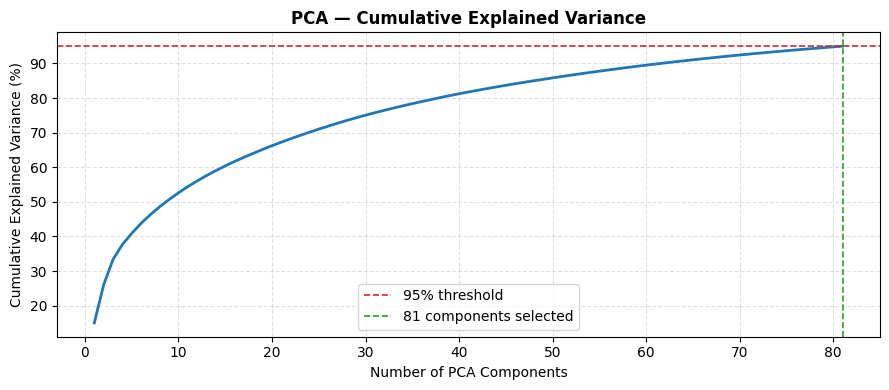

In [8]:
print('Fitting StandardScaler …')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print('Fitting PCA …')
pca = PCA(n_components=PCA_VARIANCE, random_state=SEED, svd_solver='full')
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca   = pca.transform(X_val_scaled)
X_test_pca  = pca.transform(X_test_scaled)

n_components  = pca.n_components_
var_explained = pca.explained_variance_ratio_.sum() * 100

print(f'\nPCA results:')
print(f'  Original features : {INPUT_DIM:,}')
print(f'  PCA components    : {n_components:,}  ({var_explained:.1f}% variance retained)')
print(f'  Compression ratio : {INPUT_DIM / n_components:.1f}x')
print(f'  X_train_pca shape : {X_train_pca.shape}')

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(9, 4))
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100
ax.plot(range(1, len(cum_var)+1), cum_var, color='#1f77b4', linewidth=2)
ax.axhline(95, color='#d62728', linestyle='--', linewidth=1.2, label='95% threshold')
ax.axvline(n_components, color='#2ca02c', linestyle='--', linewidth=1.2,
           label=f'{n_components} components selected')
ax.set_xlabel('Number of PCA Components')
ax.set_ylabel('Cumulative Explained Variance (%)')
ax.set_title('PCA — Cumulative Explained Variance', fontweight='bold')
ax.legend(); ax.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('pca_variance.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Train Random Forest with Grid Search + Cross-Validation

Grid search finds the best combination of:
- `n_estimators` — number of trees in the forest
- `max_depth` — maximum depth per tree (None = grow until pure)
- `min_samples_split` — minimum samples to split a node
- `min_samples_leaf` — minimum samples at a leaf node
- `max_features` — features considered at each split (`sqrt` or `log2`)

`class_weight='balanced'` handles the negative >> moderate > positive imbalance.

In [9]:
from sklearn.pipeline import Pipeline

rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=KFOLD_SPLITS, shuffle=True, random_state=SEED)

grid_search = GridSearchCV(
    estimator  = Pipeline([('rf', rf)]),
    param_grid = PARAM_GRID,
    cv         = cv,
    scoring    = 'accuracy',
    n_jobs     = -1,
    verbose    = 2,
    refit      = True,
)

print(f'Running grid search on {X_train_pca.shape[0]:,} samples '
      f'({X_train_pca.shape[1]} PCA features) …')
print('This may take several minutes.\n')

grid_search.fit(X_train_pca, y_train)

print(f'\nBest parameters  : {grid_search.best_params_}')
print(f'Best CV accuracy : {grid_search.best_score_:.4f}')

best_model = grid_search.best_estimator_

Running grid search on 1,904 samples (81 PCA features) …
This may take several minutes.

Fitting 5 folds for each of 162 candidates, totalling 810 fits

Best parameters  : {'rf__max_depth': None, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}
Best CV accuracy : 1.0000


## 10. Grid Search Results — Top Configurations

Top 10 Random Forest configurations:
                                                                                                                          Parameters Mean CV Acc Std CV Acc  Rank
 {'rf__max_depth': None, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}      1.0000     0.0000     1
   {'rf__max_depth': 20, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}      1.0000     0.0000     1
   {'rf__max_depth': 40, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}      1.0000     0.0000     1
 {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}      0.9995     0.0010     4
 {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 500}      0.9995     0.00

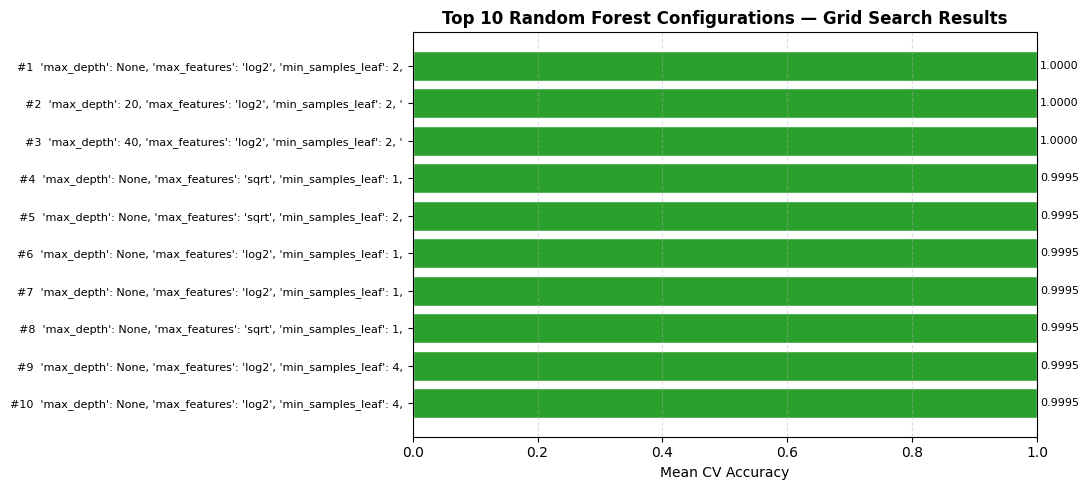

In [10]:
results_df = pd.DataFrame(grid_search.cv_results_)
results_df = results_df.sort_values('rank_test_score')

top10 = results_df[['params','mean_test_score','std_test_score','rank_test_score']].head(10).copy()
top10.columns = ['Parameters', 'Mean CV Acc', 'Std CV Acc', 'Rank']
top10['Mean CV Acc'] = top10['Mean CV Acc'].map('{:.4f}'.format)
top10['Std CV Acc']  = top10['Std CV Acc'].map('{:.4f}'.format)

print('Top 10 Random Forest configurations:')
print(top10.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(11, 5))
top_scores = results_df['mean_test_score'].head(10).values
top_labels = [str(p) for p in results_df['params'].head(10).values]
top_labels = [l.replace('rf__','').replace('{','').replace('}','') for l in top_labels]

bars = ax.barh(range(len(top_scores)), top_scores, color='#2ca02c', edgecolor='white')
ax.set_yticks(range(len(top_scores)))
ax.set_yticklabels([f'#{i+1}  {l[:65]}' for i, l in enumerate(top_labels)], fontsize=8)
ax.set_xlabel('Mean CV Accuracy')
ax.set_title('Top 10 Random Forest Configurations — Grid Search Results', fontweight='bold')
ax.set_xlim(0, 1)
ax.invert_yaxis()
for bar, score in zip(bars, top_scores):
    ax.text(score + 0.005, bar.get_y() + bar.get_height()/2,
            f'{score:.4f}', va='center', fontsize=8)
ax.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('grid_search_results.png', dpi=120, bbox_inches='tight')
plt.show()

## 11. Feature Importance (PCA Components)

Random Forest gives a `feature_importances_` score for each PCA component —
how much each component contributed to reducing impurity across all trees.
We also visualise what the top PCA components *look like* as images.

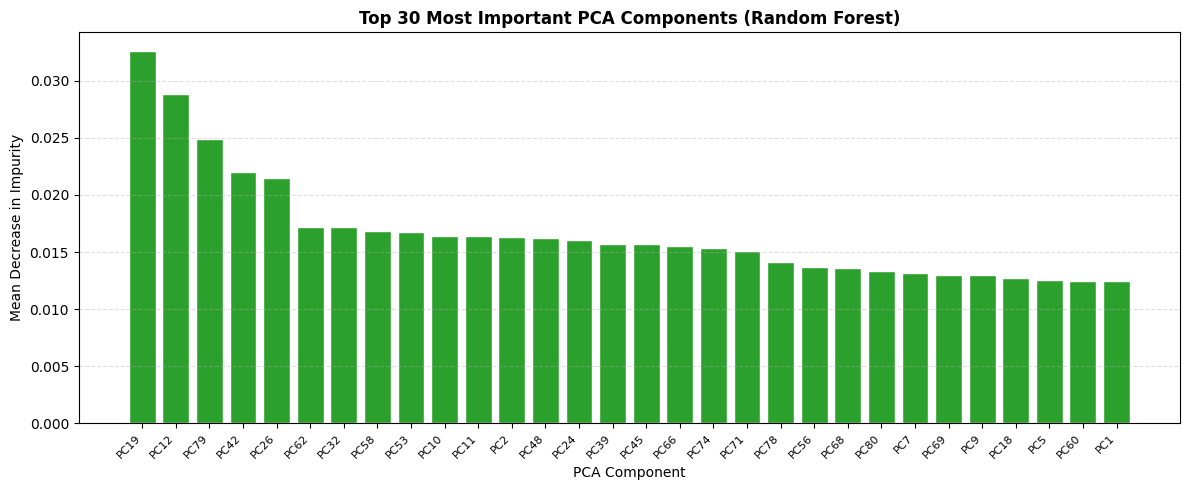

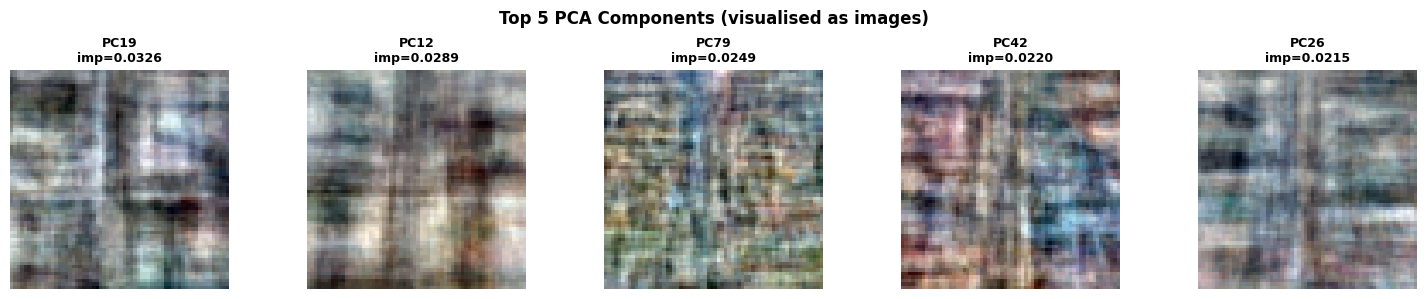

In [11]:
# ── Bar chart: importance of each PCA component ───────────────────────────────
best_rf      = best_model.named_steps['rf']
importances  = best_rf.feature_importances_
top_n        = min(30, len(importances))
top_idx      = np.argsort(importances)[::-1][:top_n]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(top_n), importances[top_idx], color='#2ca02c', edgecolor='white')
ax.set_xticks(range(top_n))
ax.set_xticklabels([f'PC{i+1}' for i in top_idx], rotation=45, ha='right', fontsize=8)
ax.set_xlabel('PCA Component')
ax.set_ylabel('Mean Decrease in Impurity')
ax.set_title(f'Top {top_n} Most Important PCA Components (Random Forest)', fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Visualise top-5 PCA components as images (eigenfaces-style) ───────────────
n_show = min(5, n_components)
fig, axes = plt.subplots(1, n_show, figsize=(n_show * 3, 3))
fig.suptitle('Top 5 PCA Components (visualised as images)', fontweight='bold')

for i, ax in enumerate(axes):
    comp = pca.components_[top_idx[i]]           # shape: (INPUT_DIM,)
    img  = comp.reshape(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
    # Normalise to [0,1] for display
    img  = (img - img.min()) / (img.max() - img.min() + 1e-8)
    ax.imshow(img)
    ax.set_title(f'PC{top_idx[i]+1}\nimp={importances[top_idx[i]]:.4f}',
                 fontsize=9, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('pca_components.png', dpi=120, bbox_inches='tight')
plt.show()

## 12. Evaluate on Validation + Test Sets

In [12]:
train_preds = best_model.predict(X_train_pca)
val_preds   = best_model.predict(X_val_pca)
test_preds  = best_model.predict(X_test_pca)

train_proba = best_model.predict_proba(X_train_pca)
val_proba   = best_model.predict_proba(X_val_pca)
test_proba  = best_model.predict_proba(X_test_pca)

train_acc  = accuracy_score(y_train, train_preds)
val_acc    = accuracy_score(y_val,   val_preds)
test_acc   = accuracy_score(y_test,  test_preds)
train_loss = log_loss(y_train, train_proba)
val_loss   = log_loss(y_val,   val_proba)
test_loss  = log_loss(y_test,  test_proba)

print(f'{"="*52}')
print(f'  Train      — Loss: {train_loss:.4f}   Acc: {train_acc:.4f}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{"="*52}')

  Train      — Loss: 0.0439   Acc: 1.0000
  Validation — Loss: 0.9408   Acc: 0.5833
  Test       — Loss: 1.0289   Acc: 0.5417


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.57      1.00      0.72        13
    moderate       0.00      0.00      0.00         6
    positive       0.00      0.00      0.00         5

    accuracy                           0.54        24
   macro avg       0.19      0.33      0.24        24
weighted avg       0.31      0.54      0.39        24



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


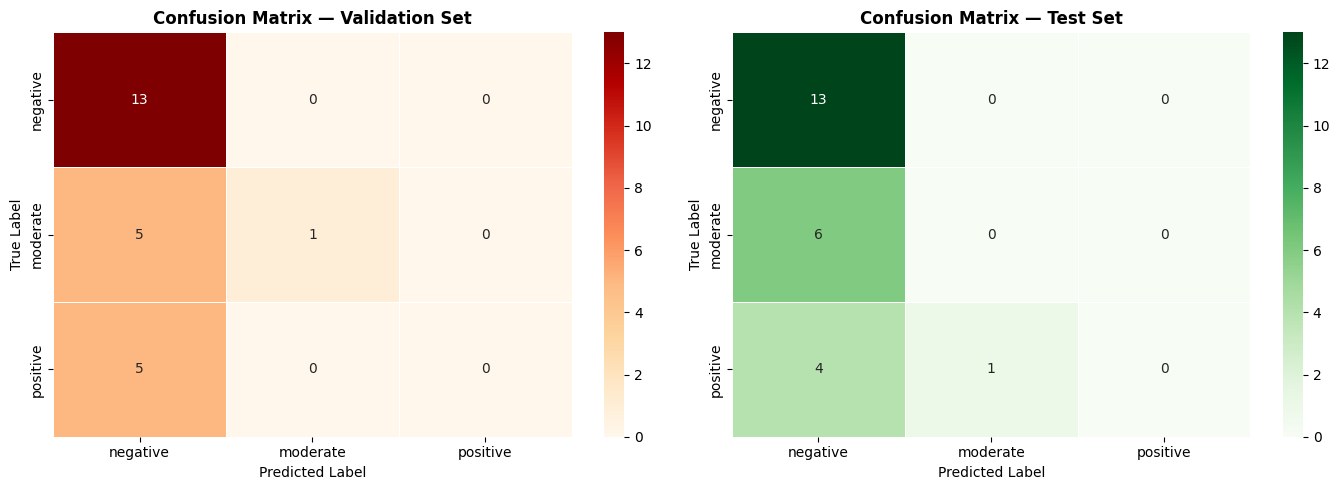

In [13]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(y_test, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  y_val,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, y_test, 'Confusion Matrix — Test Set',       'Greens'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 14. Learning Curves — Error vs. Dataset Size

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |

In [14]:
best_params = {k.replace('rf__', ''): v
               for k, v in grid_search.best_params_.items()}

curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(X_train_pca):
        print(f'  n={n}: exceeds train size ({len(X_train_pca)}), skipping.')
        break

    sub_idx, _ = train_test_split(
        np.arange(len(X_train_pca)),
        train_size=n,
        random_state=SEED,
        stratify=y_train
    )
    X_sub = X_train_pca[sub_idx]
    y_sub = y_train[sub_idx]

    rf_sub = RandomForestClassifier(
        **best_params,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1
    )
    rf_sub.fit(X_sub, y_sub)

    tr_l = log_loss(y_sub,  rf_sub.predict_proba(X_sub))
    vl_l = log_loss(y_val,  rf_sub.predict_proba(X_val_pca))
    te_l = log_loss(y_test, rf_sub.predict_proba(X_test_pca))

    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'  n={n:>4}  train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

  n=  50  train=0.2723  val=0.9391  test=0.9647
  n= 100  train=0.2696  val=0.9370  test=0.9847
  n= 150  train=0.2292  val=0.9689  test=1.0207
  n= 200  train=0.1853  val=0.9137  test=1.0436
  n= 250  train=0.1605  val=0.8894  test=1.0029
  n= 300  train=0.1433  val=0.9222  test=0.9109
  n= 400  train=0.1196  val=0.8843  test=0.9579
  n= 500  train=0.0991  val=0.9276  test=0.9682

Learning-curve data collected.


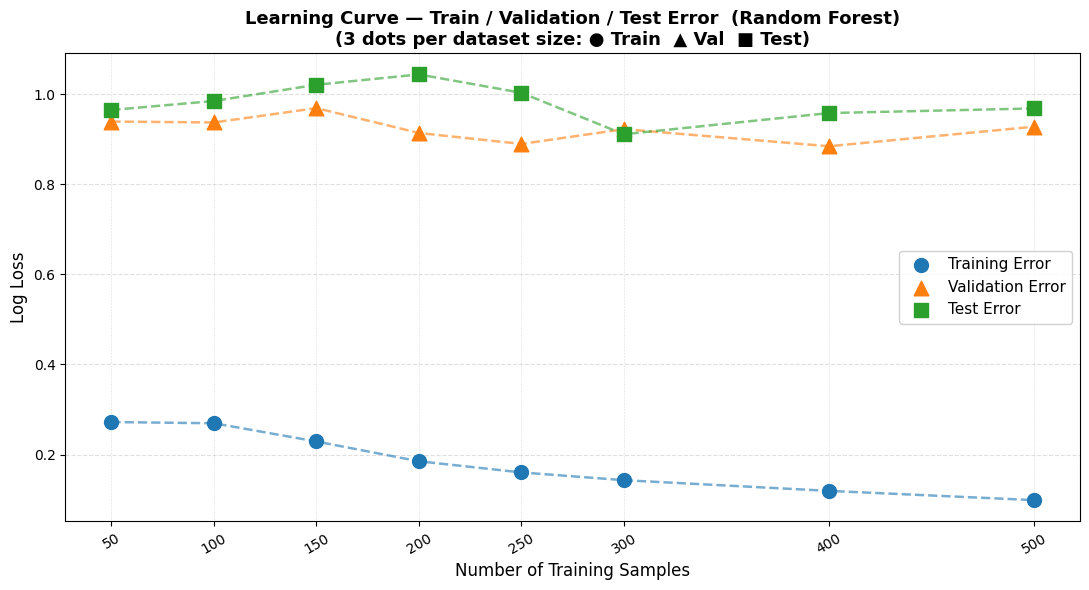

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Log Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error  (Random Forest)\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()

## 15. Save Model

In [16]:
save_path = DRIVE_BASE / 'rajuk_random_forest.pkl'

artifact = {
    'model'        : best_model,
    'scaler'       : scaler,
    'pca'          : pca,
    'best_params'  : grid_search.best_params_,
    'best_cv_acc'  : grid_search.best_score_,
    'class_names'  : CLASS_NAMES,
    'image_size'   : IMAGE_SIZE,
    'train_acc'    : train_acc,
    'val_acc'      : val_acc,
    'test_acc'     : test_acc,
    'n_pca'        : n_components,
    'label_source' : str(source_path),
}

with open(save_path, 'wb') as f:
    pickle.dump(artifact, f)

print(f'Model saved to  : {save_path}')
print(f'Best CV acc     : {grid_search.best_score_:.4f}')
print(f'Final test acc  : {test_acc:.4f}')
print(f'Best params     : {grid_search.best_params_}')

Model saved to  : /content/drive/MyDrive/ML_Project/rajuk_random_forest.pkl
Best CV acc     : 1.0000
Final test acc  : 0.5417
Best params     : {'rf__max_depth': None, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 100}


## 16. Sanity Check — Predict on Random Test Samples

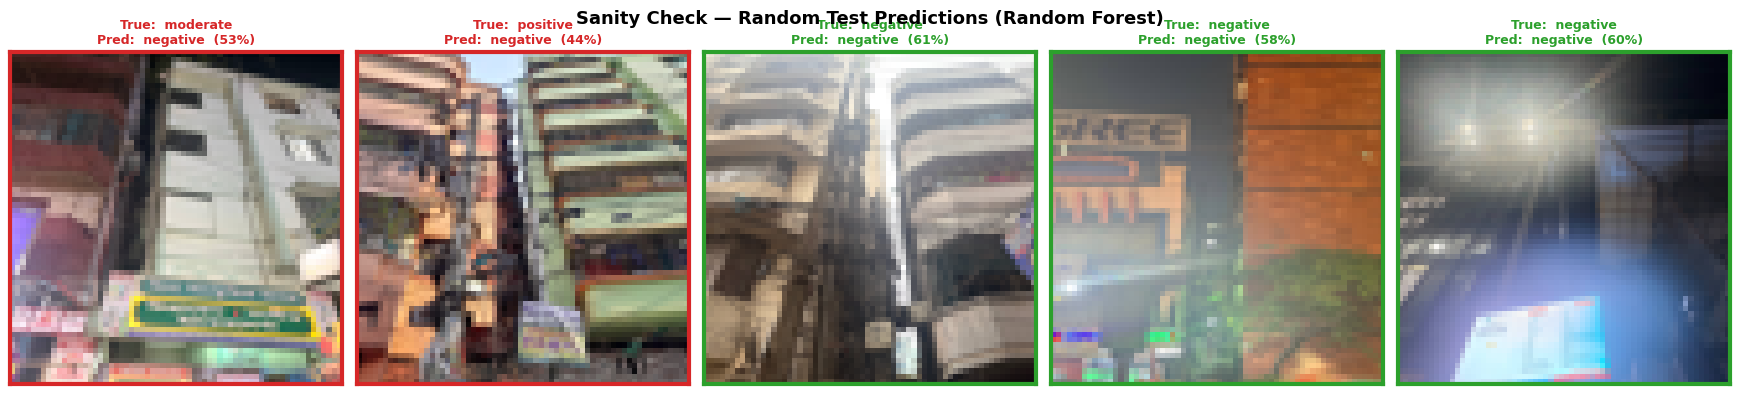

Sanity check complete.


In [17]:
def predict_image(image_path, artifact):
    with Image.open(image_path) as img:
        arr = np.asarray(
            img.convert('RGB').resize(artifact['image_size'], Image.BILINEAR),
            dtype=np.float32
        ) / 255.0
    x = arr.flatten().reshape(1, -1)
    x = artifact['scaler'].transform(x)
    x = artifact['pca'].transform(x)
    proba = artifact['model'].predict_proba(x)[0]
    pred  = artifact['class_names'][np.argmax(proba)]
    return {'prediction': pred,
            'probabilities': dict(zip(artifact['class_names'], proba.tolist()))}


rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_paths_final), size=min(5, len(test_paths_final)), replace=False)

fig, axes = plt.subplots(1, len(sample), figsize=(len(sample) * 3.5, 4))
fig.suptitle('Sanity Check — Random Test Predictions (Random Forest)',
             fontsize=13, fontweight='bold')

for ax, s_idx in zip(axes, sample):
    path      = test_paths_final[s_idx]
    true_lbl  = test_labels_final[s_idx]
    result    = predict_image(path, artifact)
    pred_name = result['prediction']
    pred_lbl  = CLASS_NAMES.index(pred_name)

    img = Image.open(path).convert('RGB').resize(IMAGE_SIZE)
    ax.imshow(np.array(img))
    ax.set_xticks([]); ax.set_yticks([])

    colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
    conf   = result['probabilities'][CLASS_NAMES[pred_lbl]]
    ax.set_title(
        f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {pred_name}  ({conf:.0%})',
        fontsize=9, color=colour, fontweight='bold'
    )
    for spine in ax.spines.values():
        spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('sanity_predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sanity check complete.')